In [1]:
!pip install -q datasets

import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from datasets import load_dataset

ds = load_dataset("yunusserhat/TurkishFoods-25")
print(ds)

class_names = ds["train"].features["label"].names
print(len(class_names), "sınıf:", class_names)

README.md:   0%|          | 0.00/6.89k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 92.8MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/eval-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 11.7MB            

data/eval-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/9168 [00:00<?, ? examples/s]

Generating eval split:   0%|          | 0/1146 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1147 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 9168
    })
    eval: Dataset({
        features: ['image', 'label'],
        num_rows: 1146
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1147
    })
})
25 sınıf: ['asure', 'baklava', 'biber_dolmasi', 'borek', 'cig_kofte', 'enginar', 'et_sote', 'gozleme', 'hamsi', 'hunkar_begendi', 'icli_kofte', 'ispanak', 'izmir_kofte', 'karniyarik', 'kebap', 'kisir', 'kuru_fasulye', 'lahmacun', 'lokum', 'manti', 'mucver', 'pirinc_pilavi', 'simit', 'taze_fasulye', 'yaprak_sarma']


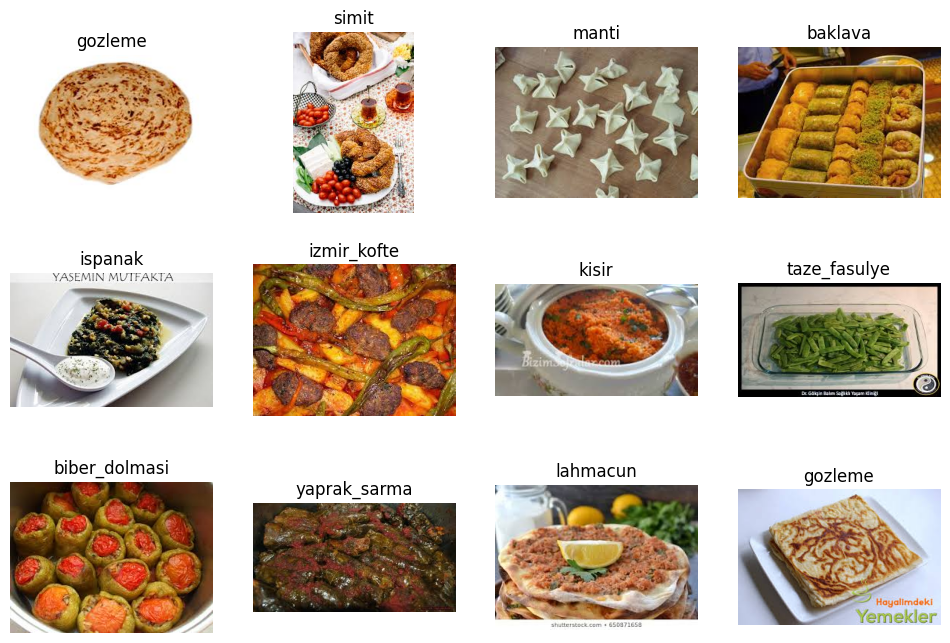

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
for i in range(12):
    ornek = ds["train"][i * 700]
    plt.subplot(3, 4, i + 1)
    plt.imshow(ornek["image"])
    plt.title(class_names[ornek["label"]])
    plt.axis("off")
plt.show()

In [4]:
import numpy as np

IMG_SIZE = 224

def to_arrays(split):
    images = np.zeros((len(split), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    labels = np.array(split["label"])
    for i, ornek in enumerate(split):
        img = ornek["image"].convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        images[i] = np.array(img)
    return images, labels

x_train, y_train = to_arrays(ds["train"])
x_val, y_val = to_arrays(ds["eval"])
x_test, y_test = to_arrays(ds["test"])

print("Train:", x_train.shape, " Val:", x_val.shape, " Test:", x_test.shape)

Train: (9168, 224, 224, 3)  Val: (1146, 224, 224, 3)  Test: (1147, 224, 224, 3)


In [5]:
sayilar = np.bincount(y_train, minlength=len(class_names))
for ad, sayi in sorted(zip(class_names, sayilar), key=lambda t: t[1]):
    print(f"{ad:15s} {sayi}")

asure           181
lahmacun        185
ispanak         213
taze_fasulye    241
hunkar_begendi  248
hamsi           253
cig_kofte       265
manti           328
et_sote         346
karniyarik      347
mucver          363
pirinc_pilavi   367
izmir_kofte     368
enginar         377
biber_dolmasi   382
kisir           388
kuru_fasulye    388
simit           391
yaprak_sarma    395
icli_kofte      402
gozleme         414
baklava         452
lokum           555
borek           613
kebap           706


In [6]:
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(x, y, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((x, y))
    if shuffle:
        dataset = dataset.shuffle(2000, seed=42)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(x_train, y_train, shuffle=True)
val_ds = make_dataset(x_val, y_val)
test_ds = make_dataset(x_test, y_test)
print("Hazır!")

Hazır!


In [7]:
from tensorflow import keras
from tensorflow.keras import layers

NUM_CLASSES = len(class_names)

# Resimleri modelin beklediği float32 tipine çeviriyoruz
def to_float(x, y):
    return tf.cast(x, tf.float32), y

train_ds = train_ds.map(to_float)
val_ds = val_ds.map(to_float)
test_ds = test_ds.map(to_float)

# Veri artırma: her epoch'ta resimleri biraz değiştiriyoruz
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

def build_model(base_model_fn, name):
    base = base_model_fn(include_top=False, weights="imagenet",
                         input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False  # gövdeyi donduruyoruz

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = data_augmentation(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3, name="dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="classifier")(x)
    return keras.Model(inputs, outputs, name=name), base

model, base = build_model(keras.applications.EfficientNetV2B0, "efficientnetv2b0")
model.summary()

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "efficientnetv2b0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 25)             │        32,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,951,337 (22.70 MB)

 Trainable params: 32,025 (125.10 KB)

 Non-trainable params: 5,919,312 (22.58 MB)

In [8]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_accuracy", patience=3, restore_best_weights=True
)

history = model.fit(train_ds, validation_data=val_ds,
                    epochs=10, callbacks=[early_stop])

Epoch 1/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 41s 85ms/step - accuracy: 0.5228 - loss: 1.7717 - val_accuracy: 0.7531 - val_loss: 1.0155
Epoch 2/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 21s 72ms/step - accuracy: 0.7200 - loss: 1.0329 - val_accuracy: 0.7976 - val_loss: 0.7921
Epoch 3/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 20s 71ms/step - accuracy: 0.7508 - loss: 0.8712 - val_accuracy: 0.8089 - val_loss: 0.7060
Epoch 4/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 20s 70ms/step - accuracy: 0.7745 - loss: 0.7903 - val_accuracy: 0.8246 - val_loss: 0.6495
Epoch 5/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 20s 70ms/step - accuracy: 0.7820 - loss: 0.7425 - val_accuracy: 0.8394 - val_loss: 0.6159
Epoch 6/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 20s 71ms/step - accuracy: 0.7969 - loss: 0.6904 - val_accuracy: 0.8447 - val_loss: 0.5929
Epoch 7/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 20s 71ms/step - accuracy: 0.7947 - loss: 0.6797 - val_accuracy: 0.8508 - val_loss: 0.5704
Epoch 8/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 20s 71ms/step - accuracy: 0.8105 - loss: 0.6416 - 

In [9]:
base.trainable = True

# Son 40 katman hariç hepsini dondurmaya devam et
for layer in base.layers[:-40]:
    layer.trainable = False

# BatchNormalization katmanlarını dondurulmuş tut
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history_fine = model.fit(train_ds, validation_data=val_ds,
                         epochs=10, callbacks=[early_stop])

Epoch 1/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 37s 89ms/step - accuracy: 0.8370 - loss: 0.5436 - val_accuracy: 0.8656 - val_loss: 0.4842
Epoch 2/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 23s 80ms/step - accuracy: 0.8541 - loss: 0.4863 - val_accuracy: 0.8700 - val_loss: 0.4665
Epoch 3/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 23s 79ms/step - accuracy: 0.8638 - loss: 0.4535 - val_accuracy: 0.8822 - val_loss: 0.4446
Epoch 4/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 23s 79ms/step - accuracy: 0.8693 - loss: 0.4278 - val_accuracy: 0.8752 - val_loss: 0.4388
Epoch 5/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 23s 81ms/step - accuracy: 0.8790 - loss: 0.4068 - val_accuracy: 0.8822 - val_loss: 0.4303
Epoch 6/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 23s 80ms/step - accuracy: 0.8898 - loss: 0.3726 - val_accuracy: 0.8857 - val_loss: 0.4231
Epoch 7/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 23s 80ms/step - accuracy: 0.8983 - loss: 0.3414 - val_accuracy: 0.8892 - val_loss: 0.4224
Epoch 8/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 23s 81ms/step - accuracy: 0.8990 - loss: 0.3353 - 

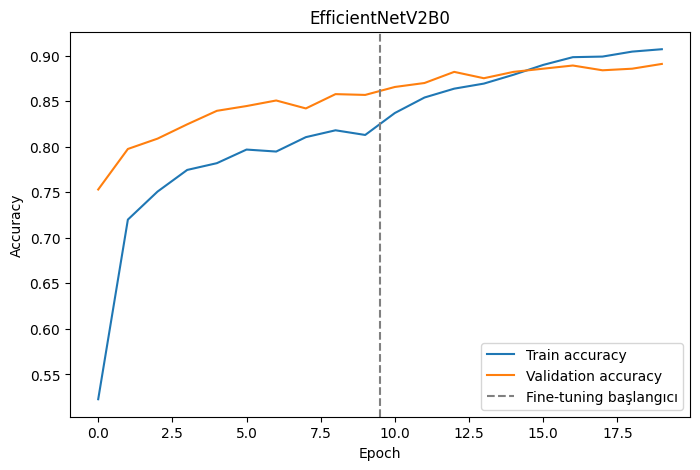

Test accuracy: 0.8614


In [10]:
# Öğrenme eğrileri
acc = history.history["accuracy"] + history_fine.history["accuracy"]
val_acc = history.history["val_accuracy"] + history_fine.history["val_accuracy"]
ilk_asama = len(history.history["accuracy"])

plt.figure(figsize=(8, 5))
plt.plot(acc, label="Train accuracy")
plt.plot(val_acc, label="Validation accuracy")
plt.axvline(ilk_asama - 0.5, color="gray", linestyle="--", label="Fine-tuning başlangıcı")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNetV2B0")
plt.legend()
plt.show()

# Test seti: modelin hiç görmediği resimler
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")

In [11]:
from google.colab import drive
import os

drive.mount("/content/drive")
SAVE_DIR = "/content/drive/MyDrive/turkish_food"
os.makedirs(SAVE_DIR, exist_ok=True)
model.save(f"{SAVE_DIR}/efficientnetv2b0.keras")
print("Kaydedildi!")

Mounted at /content/drive
Kaydedildi!


In [12]:
def train_model(base_model_fn, name, head_epochs=10, fine_epochs=10, unfreeze=40):
    model_, base_ = build_model(base_model_fn, name)
    early_stop_ = keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=3, restore_best_weights=True)

    # 1. aşama: sadece kafa
    model_.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model_.fit(train_ds, validation_data=val_ds,
               epochs=head_epochs, callbacks=[early_stop_])

    # 2. aşama: fine-tuning
    base_.trainable = True
    for layer in base_.layers[:-unfreeze]:
        layer.trainable = False
    for layer in base_.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    model_.compile(optimizer=keras.optimizers.Adam(5e-5),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model_.fit(train_ds, validation_data=val_ds,
               epochs=fine_epochs, callbacks=[early_stop_])

    test_acc = model_.evaluate(test_ds, verbose=0)[1]
    print(f"\n{name} test accuracy: {test_acc:.4f}")
    model_.save(f"{SAVE_DIR}/{name}.keras")
    return model_

In [13]:
mobilenet = train_model(keras.applications.MobileNetV3Large, "mobilenetv3large")

12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 25s 63ms/step - accuracy: 0.4725 - loss: 1.8419 - val_accuracy: 0.7426 - val_loss: 0.8859
Epoch 2/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 16s 57ms/step - accuracy: 0.6872 - loss: 1.0467 - val_accuracy: 0.7958 - val_loss: 0.7150
Epoch 3/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 16s 56ms/step - accuracy: 0.7393 - loss: 0.8714 - val_accuracy: 0.8019 - val_loss: 0.6406
Epoch 4/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 16s 57ms/step - accuracy: 0.7580 - loss: 0.7985 - val_accuracy: 0.8141 - val_loss: 0.6261
Epoch 5/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 16s 56ms/step - accuracy: 0.7695 - loss: 0.7503 - val_accuracy: 0.8194 - val_loss: 0.6150
Epoch 6/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 16s 57ms/step - accuracy: 0.7741 - loss: 0.7231 - val_accuracy: 0.8229 - val_loss: 0.6011
Epoch 7/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 21s 57ms/step - accuracy: 0.7900 - loss: 0.6901 - val_accuracy: 0.8307 - val_loss: 0.5782
Epoch 8/10
287/287 ━━━━━━━━━━━━━━━━━━━━

In [14]:
convnext = train_model(keras.applications.ConvNeXtTiny, "convnexttiny",
                       head_epochs=6, fine_epochs=6)

111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/6
287/287 ━━━━━━━━━━━━━━━━━━━━ 116s 361ms/step - accuracy: 0.4545 - loss: 1.9787 - val_accuracy: 0.7016 - val_loss: 1.2092
Epoch 2/6
287/287 ━━━━━━━━━━━━━━━━━━━━ 98s 341ms/step - accuracy: 0.6770 - loss: 1.1875 - val_accuracy: 0.7504 - val_loss: 0.9554
Epoch 3/6
287/287 ━━━━━━━━━━━━━━━━━━━━ 100s 349ms/step - accuracy: 0.7252 - loss: 1.0050 - val_accuracy: 0.7723 - val_loss: 0.8477
Epoch 4/6
287/287 ━━━━━━━━━━━━━━━━━━━━ 101s 352ms/step - accuracy: 0.7412 - loss: 0.9052 - val_accuracy: 0.7845 - val_loss: 0.7811
Epoch 5/6
287/287 ━━━━━━━━━━━━━━━━━━━━ 102s 355ms/step - accuracy: 0.7645 - loss: 0.8405 - val_accuracy: 0.8010 - val_loss: 0.7504
Epoch 6/6
287/287 ━━━━━━━━━━━━━━━━━━━━ 102s 355ms/step - accuracy: 0.7667 - loss: 0.8009 - val_accuracy: 0.8080 - val_loss: 0.7085
Epoch 1/6
287/287 ━━━━━━━━━━━━━━━━━━━━ 231s 752ms/step - accuracy: 0.8273 - loss: 0.6053 - val_accuracy: 0.8735 - val_loss: 0.4843
Epoch 2/6
287/287 ━━━━━━━━━━━━━

In [15]:
print("EfficientNetV2B0 test accuracy:", round(model.evaluate(test_ds, verbose=0)[1], 4))

EfficientNetV2B0 test accuracy: 0.8614


In [16]:
modeller = {
    "EfficientNetV2B0": model,
    "MobileNetV3Large": mobilenet,
    "ConvNeXtTiny": convnext,
}

# Her modelin validation ve test tahminleri (olasılıklar)
val_probs = {ad: m.predict(val_ds, verbose=0) for ad, m in modeller.items()}
test_probs = {ad: m.predict(test_ds, verbose=0) for ad, m in modeller.items()}

def accuracy(probs, y):
    return (probs.argmax(axis=1) == y).mean()

for ad in modeller:
    print(f"{ad:22s} val: {accuracy(val_probs[ad], y_val):.4f}   test: {accuracy(test_probs[ad], y_test):.4f}")

ens_val = np.mean(list(val_probs.values()), axis=0)
ens_test = np.mean(list(test_probs.values()), axis=0)
print(f"{'Ensemble (ortalama)':22s} val: {accuracy(ens_val, y_val):.4f}   test: {accuracy(ens_test, y_test):.4f}")

EfficientNetV2B0       val: 0.8909   test: 0.8614
MobileNetV3Large       val: 0.8813   test: 0.8640
ConvNeXtTiny           val: 0.8997   test: 0.9137
Ensemble (ortalama)    val: 0.9171   test: 0.9015


In [17]:
adlar = list(modeller)
en_iyi_acc, en_iyi_w = 0, None

for w1 in np.arange(0, 1.01, 0.1):
    for w2 in np.arange(0, 1.01 - w1, 0.1):
        w3 = max(0.0, 1 - w1 - w2)
        p = w1 * val_probs[adlar[0]] + w2 * val_probs[adlar[1]] + w3 * val_probs[adlar[2]]
        a = accuracy(p, y_val)
        if a > en_iyi_acc:
            en_iyi_acc, en_iyi_w = a, (round(w1, 1), round(w2, 1), round(w3, 1))

print("En iyi ağırlıklar (validation'a göre):", dict(zip(adlar, en_iyi_w)))
print(f"Validation accuracy: {en_iyi_acc:.4f}")

w1, w2, w3 = en_iyi_w
weighted_test = w1 * test_probs[adlar[0]] + w2 * test_probs[adlar[1]] + w3 * test_probs[adlar[2]]
print(f"Ağırlıklı ensemble TEST accuracy: {accuracy(weighted_test, y_test):.4f}")

En iyi ağırlıklar (validation'a göre): {'EfficientNetV2B0': np.float64(0.3), 'MobileNetV3Large': np.float64(0.2), 'ConvNeXtTiny': np.float64(0.5)}
Validation accuracy: 0.9188
Ağırlıklı ensemble TEST accuracy: 0.9137


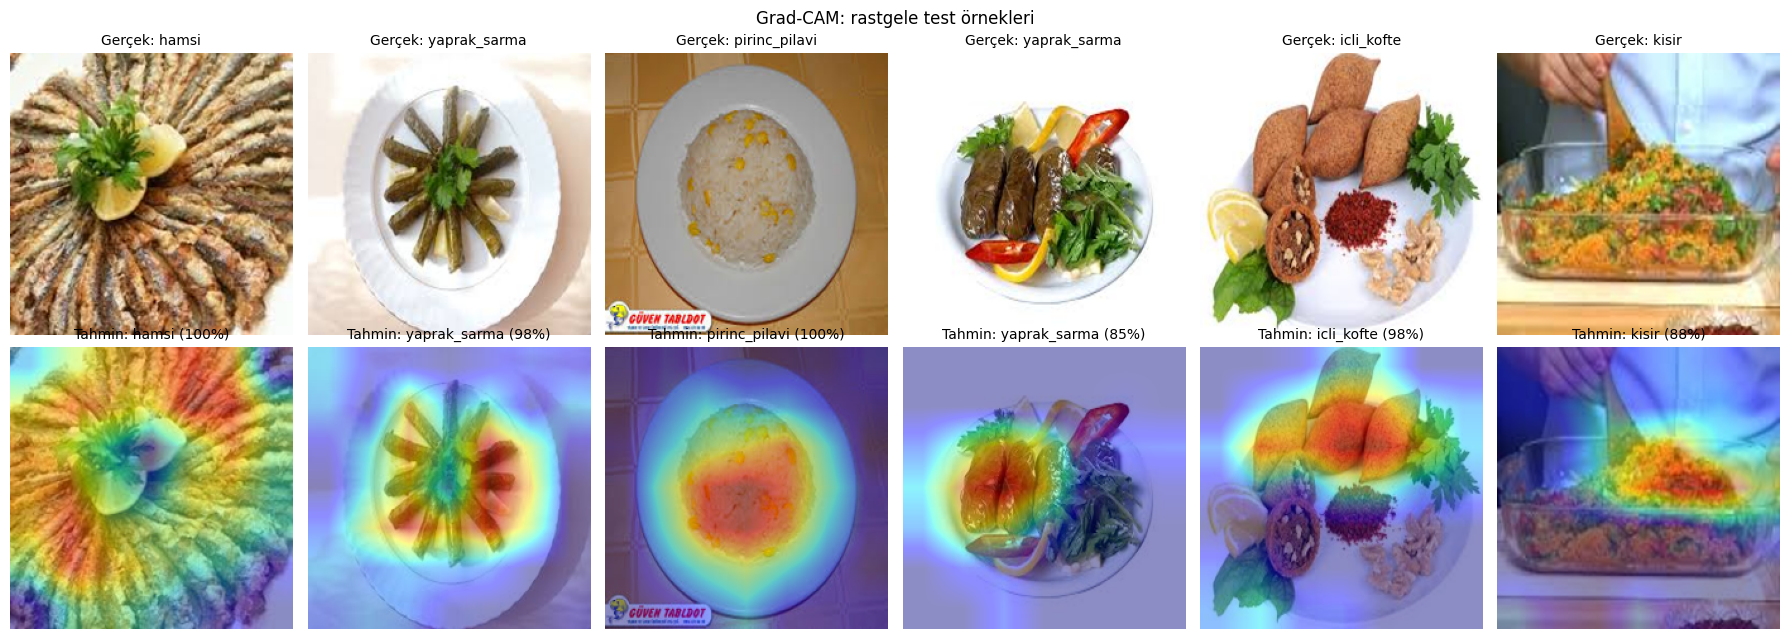

99 yanlış tahmin var


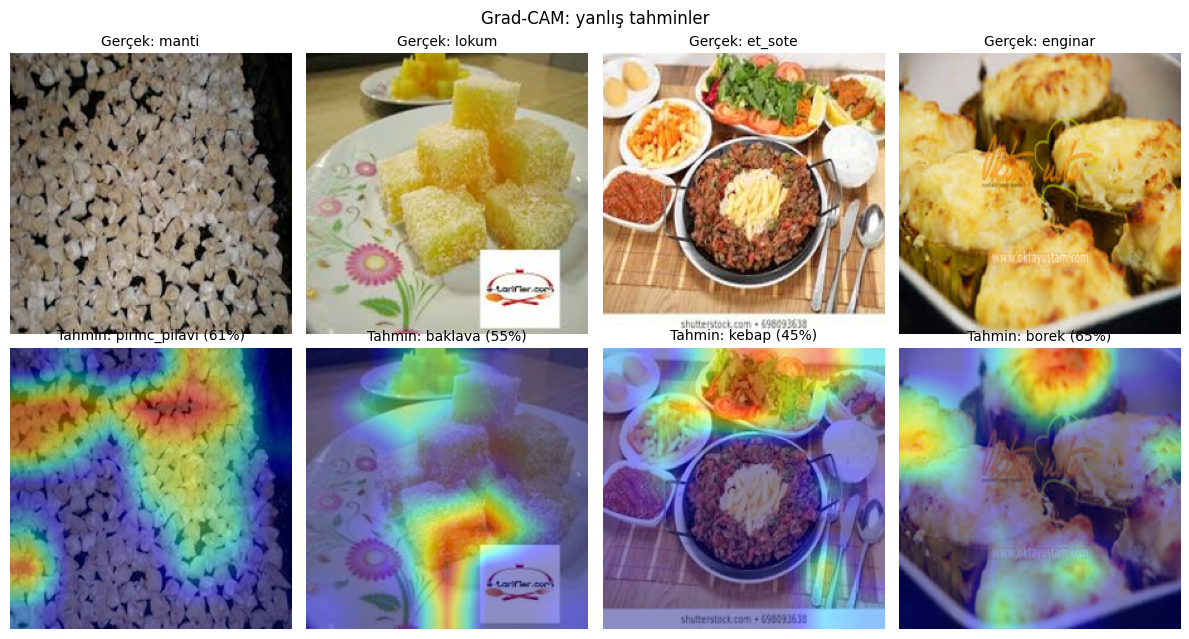

In [19]:
def grad_cam(m, img):
    base_layer = [l for l in m.layers
                  if isinstance(l, keras.Model) and l.name != "augmentation"][0]
    gap, clf = m.get_layer("gap"), m.get_layer("classifier")
    x = tf.convert_to_tensor(img[None].astype("float32"))

    with tf.GradientTape() as tape:
        feats = base_layer(x, training=False)
        tape.watch(feats)
        preds = clf(gap(feats))
        cls = tf.argmax(preds[0])
        score = preds[:, cls]

    grads = tape.gradient(score, feats)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.reduce_sum(feats * weights[:, None, None, :], axis=-1)[0]
    cam = tf.nn.relu(cam) / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE))[..., 0].numpy()
    return cam, int(cls), float(preds[0, cls])

def show_gradcam(indices, title, filename):
    n = len(indices)
    plt.figure(figsize=(3 * n, 6.5))
    for j, i in enumerate(indices):
        cam, pred, conf = grad_cam(convnext, x_test[i])
        plt.subplot(2, n, j + 1)
        plt.imshow(x_test[i]); plt.axis("off")
        plt.title(f"Gerçek: {class_names[y_test[i]]}", fontsize=10)
        plt.subplot(2, n, n + j + 1)
        plt.imshow(x_test[i]); plt.imshow(cam, cmap="jet", alpha=0.45); plt.axis("off")
        plt.title(f"Tahmin: {class_names[pred]} ({conf:.0%})", fontsize=10)
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(f"{SAVE_DIR}/{filename}", dpi=120, bbox_inches="tight")
    plt.show()

# Rastgele 6 test fotoğrafı
rng = np.random.default_rng(7)
show_gradcam(rng.choice(len(x_test), 6, replace=False),
             "Grad-CAM: rastgele test örnekleri", "gradcam_examples.png")

# Modelin yanıldığı 4 fotoğraf
conv_pred = test_probs["ConvNeXtTiny"].argmax(axis=1)
yanlislar = np.where(conv_pred != y_test)[0]
print(len(yanlislar), "yanlış tahmin var")
show_gradcam(yanlislar[:4], "Grad-CAM: yanlış tahminler", "gradcam_mistakes.png")